# Polynomial Regression with GridSearchCV

**Goal:** predict a car's fuel efficiency (`mpg`, miles per gallon) from its engine power (`horsepower`).

**Dataset:** the classic *Auto MPG* dataset (398 cars from the 1970s and 80s), loaded directly from `seaborn`.

**What we'll do:**
1. Load and look at the data
2. Fit a straight line (linear regression) and see where it fails
3. See what `PolynomialFeatures` actually does to our data
4. Compare different degrees visually (and spot overfitting)
5. Use `GridSearchCV` to pick the best degree automatically
6. Evaluate the best model on unseen test data

## 1. Imports

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_squared_error, r2_score

## 2. Load the dataset

In [2]:
df = sns.load_dataset("mpg")
print(df.shape)
df.head()

(398, 9)


,mpg,cylinders,displacement,horsepower,weight,acceleration,model_year,origin,name
0,18.0,8,307.0,130.0,3504,12.0,70,usa,chevrolet chevelle malibu
1,15.0,8,350.0,165.0,3693,11.5,70,usa,buick skylark 320
2,18.0,8,318.0,150.0,3436,11.0,70,usa,plymouth satellite
3,16.0,8,304.0,150.0,3433,12.0,70,usa,amc rebel sst
4,17.0,8,302.0,140.0,3449,10.5,70,usa,ford torino


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 398 entries, 0 to 397
Data columns (total 9 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   mpg           398 non-null    float64
 1   cylinders     398 non-null    int64  
 2   displacement  398 non-null    float64
 3   horsepower    392 non-null    float64
 4   weight        398 non-null    int64  
 5   acceleration  398 non-null    float64
 6   model_year    398 non-null    int64  
 7   origin        398 non-null    str    
 8   name          398 non-null    str    
dtypes: float64(4), int64(3), str(2)
memory usage: 35.9 KB


In [4]:
# horsepower has a few missing values, so we drop those rows
df = df.dropna(subset=["horsepower"])
print("Rows:", len(df))

Rows: 392


### Look at the data first
Before choosing any model, always plot the data. Does it look like a straight line?

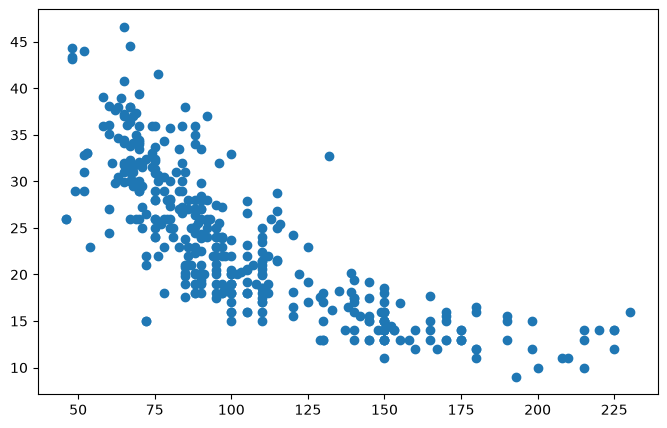

In [5]:
plt.figure(figsize=(8, 5))
plt.scatter(df["horsepower"], df["mpg"])


**Observation:** MPG drops quickly at first, then the drop slows down and flattens out.
That's a **curve**, not a straight line. Keep this in mind.

## 3. Prepare X and y, then split into train and test

In [ ]:
X = df[["horsepower"]]
y = df["mpg"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)
print("Train size:", len(X_train), "| Test size:", len(X_test))

Train size: 313 | Test size: 79


## 4. Baseline: plain linear regression (a straight line)

In [ ]:
lin_model = LinearRegression()
lin_model.fit(X_train, y_train)

y_pred = lin_model.predict(X_test)
print("Linear regression")
print("  R2 score :", round(r2_score(y_test, y_pred), 3))
print("  RMSE     :", round(np.sqrt(mean_squared_error(y_test, y_pred)), 3))

Linear regression
  R2 score : 0.566
  RMSE     : 4.707


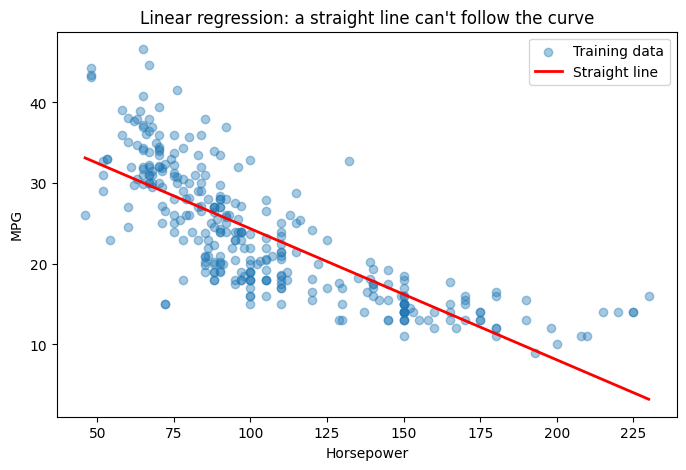

In [ ]:
# A smooth range of horsepower values, used only for drawing lines/curves
x_range = pd.DataFrame({"horsepower": np.linspace(X["horsepower"].min(), X["horsepower"].max(), 300)})

plt.figure(figsize=(8, 5))
plt.scatter(X_train, y_train, alpha=0.4, label="Training data")
plt.plot(x_range, lin_model.predict(x_range), color="red", linewidth=2, label="Straight line")
plt.xlabel("Horsepower")
plt.ylabel("MPG")
plt.title("Linear regression: a straight line can't follow the curve")
plt.legend()
plt.show()

**Observation:** the line is too high in the middle and too low at both ends. It can't bend.

## 5. What does `PolynomialFeatures` actually do?

Polynomial regression = **add new columns** (x², x³, ...) and then run **ordinary linear regression** on them.

Let's see it with 3 rows of data.

In [ ]:
sample = X_train.head(3)

poly = PolynomialFeatures(degree=3, include_bias=False)
sample_poly = poly.fit_transform(sample)
print(sample_poly.shape)

pd.DataFrame(sample_poly, columns=poly.get_feature_names_out(), index=sample.index)

(3, 3)


,horsepower,horsepower^2,horsepower^3
260,110.0,12100.0,1331000.0
184,92.0,8464.0,778688.0
174,97.0,9409.0,912673.0


One column (`horsepower`) became three columns: `horsepower`, `horsepower^2`, `horsepower^3`.

Linear regression then learns one coefficient for each column:

    mpg = a + b·hp + c·hp² + d·hp³

Those extra squared and cubed columns are what let the line **bend**.

## 6. Build a pipeline: PolynomialFeatures → StandardScaler → LinearRegression

A **pipeline** chains steps together so they always run in the same order.

Why `StandardScaler`? With horsepower around 200, hp³ is 8,000,000 and hp¹⁰ is astronomically large.
Scaling brings all columns to a similar range so the maths stays stable.

In [ ]:
def make_poly_model(degree):
    return Pipeline([
        ("poly", PolynomialFeatures(degree=degree, include_bias=False)),
        ("scaler", StandardScaler()),
        ("linreg", LinearRegression()),
    ])

# Try degree 2
poly2 = make_poly_model(2)
poly2.fit(X_train, y_train)

y_pred2 = poly2.predict(X_test)
print("Polynomial regression (degree 2)")
print("  R2 score :", round(r2_score(y_test, y_pred2), 3))
print("  RMSE     :", round(np.sqrt(mean_squared_error(y_test, y_pred2)), 3))

Polynomial regression (degree 2)
  R2 score : 0.639
  RMSE     : 4.291


Compare this with the straight line above: the error (RMSE) drops and R² goes up,
just by adding the hp² column.

## 7. Compare several degrees visually

Let's draw degree 1, 2, 3 and 15 side by side.

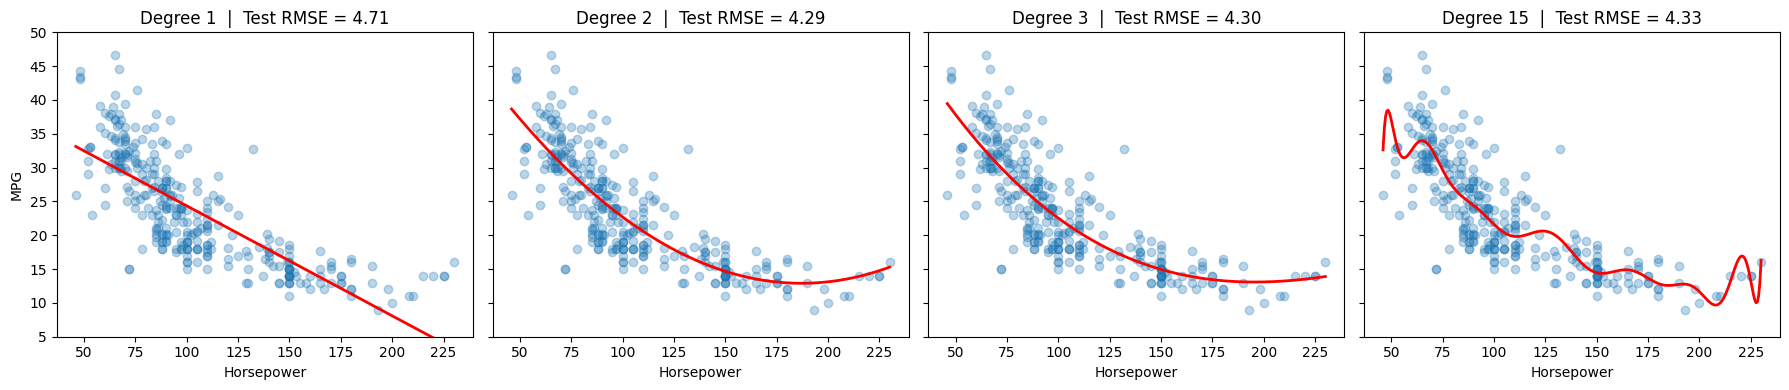

In [ ]:
degrees_to_show = [1, 2, 3, 15]

fig, axes = plt.subplots(1, 4, figsize=(18, 4), sharey=True)
for ax, d in zip(axes, degrees_to_show):
    model = make_poly_model(d)
    model.fit(X_train, y_train)
    test_rmse = np.sqrt(mean_squared_error(y_test, model.predict(X_test)))

    ax.scatter(X_train, y_train, alpha=0.3)
    ax.plot(x_range, model.predict(x_range), color="red", linewidth=2)
    ax.set_title(f"Degree {d}  |  Test RMSE = {test_rmse:.2f}")
    ax.set_xlabel("Horsepower")
    ax.set_ylim(5, 50)
axes[0].set_ylabel("MPG")
plt.tight_layout()
plt.show()

**Observations:**
- **Degree 1:** too simple, can't bend (*underfitting*).
- **Degree 2 or 3:** follows the curve nicely.
- **Degree 15:** wiggles, especially at the edges, chasing individual points (*overfitting*).

So which degree is best? Guessing by eye isn't reliable. Let **GridSearchCV** decide.

## 8. Tune the degree with GridSearchCV

**How GridSearchCV works:**
1. We give it a list of degrees to try (the "grid").
2. For each degree, it does **5-fold cross-validation**: it splits the *training* data into 5 parts,
   trains on 4 parts, tests on the 5th, and repeats 5 times so every part gets a turn as the test part.
3. It averages the 5 scores for each degree and picks the degree with the best average.

Note: the **test set is never touched** during this search. We keep it for the final check.

In [ ]:
pipeline = make_poly_model(degree=1)   # the degree here will be overridden by the grid

param_grid = {
    "poly__degree": list(range(1, 11))   # "poly" is the step name, "degree" is its parameter
}

grid = GridSearchCV(
    estimator=pipeline,
    param_grid=param_grid,
    cv=5,
    scoring="neg_root_mean_squared_error",   # scikit-learn maximises scores, so error is made negative
)

grid.fit(X_train, y_train)

print("Best degree :", grid.best_params_["poly__degree"])
print("Best CV RMSE:", round(-grid.best_score_, 3))

Best degree : 2
Best CV RMSE: 4.37


### Look at the score for every degree

In [ ]:
results = pd.DataFrame({
    "degree": grid.cv_results_["param_poly__degree"],
    "cv_rmse": -grid.cv_results_["mean_test_score"],
    "std_across_folds": grid.cv_results_["std_test_score"],
}).round(3)
results

,degree,cv_rmse,std_across_folds
0,1,4.936,0.570
1,2,4.370,0.624
2,3,4.374,0.640
3,4,4.399,0.637
4,5,4.380,0.588
5,6,4.394,0.598
6,7,4.396,0.602
7,8,4.430,0.647
8,9,4.443,0.800
9,10,4.583,0.902


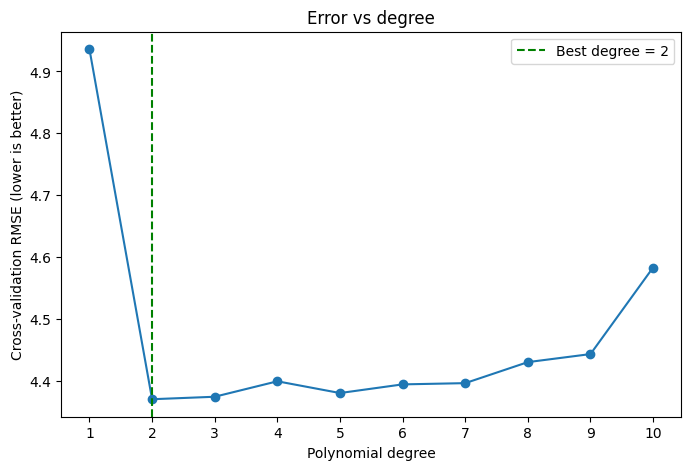

In [ ]:
plt.figure(figsize=(8, 5))
plt.plot(results["degree"], results["cv_rmse"], marker="o")
best_d = grid.best_params_["poly__degree"]
plt.axvline(best_d, color="green", linestyle="--", label=f"Best degree = {best_d}")
plt.xlabel("Polynomial degree")
plt.ylabel("Cross-validation RMSE (lower is better)")
plt.title("Error vs degree")
plt.xticks(results["degree"])
plt.legend()
plt.show()

**Reading this plot:** the error falls sharply from degree 1 to 2 (the line learns to bend),
then stays roughly flat or creeps back up as the degree grows. Extra degrees add complexity
without adding real accuracy.

> **Teaching tip:** if two degrees score almost the same, prefer the **simpler** (lower) one.
> It is easier to explain and less likely to overfit new data.

## 9. Final evaluation on the test set

In [ ]:
best_model = grid.best_estimator_   # already refitted on the full training set

y_pred_best = best_model.predict(X_test)
print(f"Best model (degree {best_d}) on the test set")
print("  R2 score :", round(r2_score(y_test, y_pred_best), 3))
print("  RMSE     :", round(np.sqrt(mean_squared_error(y_test, y_pred_best)), 3))

Best model (degree 2) on the test set
  R2 score : 0.639
  RMSE     : 4.291


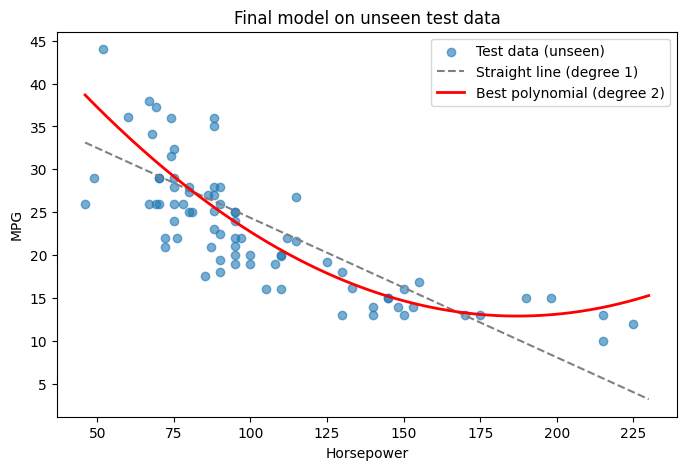

In [ ]:
plt.figure(figsize=(8, 5))
plt.scatter(X_test, y_test, alpha=0.6, label="Test data (unseen)")
plt.plot(x_range, lin_model.predict(x_range), color="gray", linestyle="--", label="Straight line (degree 1)")
plt.plot(x_range, best_model.predict(x_range), color="red", linewidth=2, label=f"Best polynomial (degree {best_d})")
plt.xlabel("Horsepower")
plt.ylabel("MPG")
plt.title("Final model on unseen test data")
plt.legend()
plt.show()

## 10. Peek inside: the sign of the x² coefficient

Remember the question "x² always goes up, so how can it bend?"
The answer is the **coefficient**: the model picks its sign from the data.

Here we fit degree 2 *without* scaling so the coefficients are easy to read.

In [ ]:
simple_poly = Pipeline([
    ("poly", PolynomialFeatures(degree=2, include_bias=False)),
    ("linreg", LinearRegression()),
])
simple_poly.fit(X_train, y_train)

a = simple_poly.named_steps["linreg"].intercept_
b, c = simple_poly.named_steps["linreg"].coef_
print(f"mpg = {a:.2f} + ({b:.4f})·hp + ({c:.6f})·hp²")
print("x² coefficient is", "POSITIVE -> valley shape (curves up)" if c > 0 else "NEGATIVE -> hill shape (curves down)")

mpg = 58.21 + (-0.4845)·hp + (0.001295)·hp²
x² coefficient is POSITIVE -> valley shape (curves up)


Here `b` is negative (MPG falls as horsepower rises) and `c` is positive (the fall slows down and flattens).
The data "voted" for a positive `c` because that shape matched it best.

## 11. Practice exercises

1. Change `range(1, 11)` in the grid to `range(1, 21)`. Does the best degree change? What happens to the error at high degrees?
2. Change `cv=5` to `cv=10`. Is the result stable?
3. Replace `horsepower` with `weight` as the input feature. Is the relationship also curved? What degree does GridSearchCV pick?
4. Remove the `StandardScaler` step and run the grid search again. Do high degrees behave worse? Why?